# DATASCI 350 - Data Science Computing

## Assignment 05 - A reproducible research note with Quarto

### Instructions

This assignment evaluates your understanding of reproducible research and Quarto, covered in lectures 10 and 11.

You will build one small, complete deliverable: a research note called "Coffee and contentment", written in Quarto, that follows every reproducibility habit from lecture 10. The dataset links coffee consumption, income, and happiness scores for 20 countries between 2010 and 2024. The data is synthetic but plausible: the note is about the machinery, not the findings.

The analysis itself is deliberately simple. Most of the Python you need appeared in the lecture 11 examples. Where a task needs more, the hint says where to look. What we grade is the document: its structure, its rendering, its citations, and whether someone else could rebuild it.

Warning: an absolute path anywhere in your project (any path containing your username) loses points, as discussed in lecture 10. Use relative paths throughout.

Before you start, confirm that `quarto check` reports a working installation, including TinyTeX for PDFs. If TinyTeX is missing, run `quarto install tinytex` once.

You must complete this assignment individually. You may use notes, books, and AI tools, but you must submit original work. I strongly recommend that you do not use AI tools to generate your solutions, as this will not help you learn the material. Acknowledge all resources used, including input from classmates and AI, in a short note at the end of your submission. If you are unsure about permissible resources or proper acknowledgement, please ask the instructor.

### Submission

Work in a project folder named `coffee-note`. When you finish, compress the whole folder into `coffee-note.zip` and submit it on Canvas. The zip must contain your `.qmd` source, the rendered HTML and PDF outputs, the `note_files/` folder that the HTML files load their figures from, both parameterised HTML files, your cleaning script, your README, and the data folders. Do not include `_site/` or `.quarto/` folders.

Answer the written question in task 11 in the answer cell of this notebook and submit the notebook too.

### Task 01

Create a project folder `coffee-note` with the folder layout from lecture 10: `data/raw`, `data/clean`, `scripts`, and `output`, plus an empty `README.md`. Then download the dataset into `data/raw` from the command line:

```bash
curl -o data/raw/coffee.csv https://raw.githubusercontent.com/danilofreire/datasci350/main/assignments/data/coffee.csv
```

Paste the commands you used into the answer cell. *Hint: one command from lecture 04 creates several nested folders at once.*

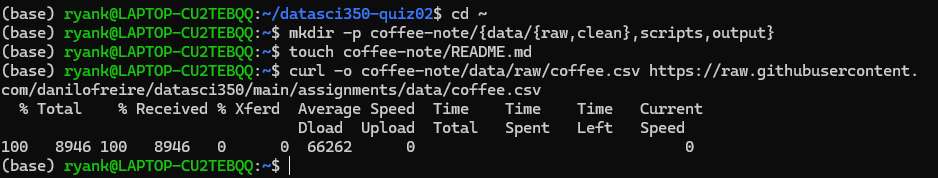

mkdir -p coffee-note/{data/{raw,clean},scripts,output}

touch coffee-note/README.md

curl -o coffee-note/data/raw/coffee.csv https://raw.githubusercontent.com/danilofreire/datasci350/main/assignments/data/coffee.csv

### Task 02

Inside `coffee-note`, create `note.qmd` with at least this metadata (later tasks add to it): title "Coffee and contentment", your name as author, the date (the special value `today` is fine), `format: html` with a table of contents enabled, and an `execute:` block that hides code and warnings for the whole document.

Below the header, write an introduction: one `##` heading, a short paragraph on what the note examines, a bulleted list of the three variables, and one footnote of your choice. *Hint: the YAML options you need are on the lecture 10 slides "The YAML header" and "The chunk options you will use most". Footnotes are on the lecture 11 slide "Markdown syntax".*

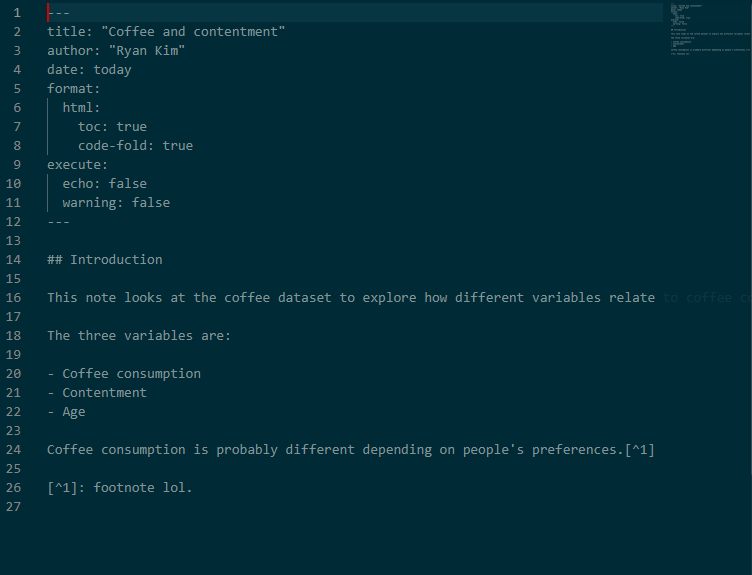

---
title: "Coffee and contentment"
author: "Ryan Kim"
date: today
format:
  html:
    toc: true
    code-fold: true
execute:
  echo: false
  warning: false
---

## Introduction

This note looks at the coffee dataset to explore how different variables relate to coffee consumption and contentment.

The three variables are:

- Coffee consumption
- Contentment
- Age

Coffee consumption is probably different depending on people's preferences.[^1]

[^1]: footnote lol.


### Task 03

Write `scripts/01-clean.py`. It must read `data/raw/coffee.csv`, keep only the years 2015 to 2024, and write the result to `data/clean/coffee-recent.csv`. Run it from the command line, from the project root:

```bash
python scripts/01-clean.py
```

If your terminal says `python` is not found, use `python3`.

Paste the script into the answer cell. The raw file stays untouched. *Hint: `pandas` reads and writes CSVs with two functions whose names you can guess; filtering rows was in the lecture 11 report example. Write the CSV with `index=False`, or pandas adds a column of row numbers.*


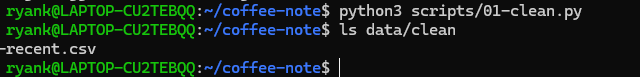
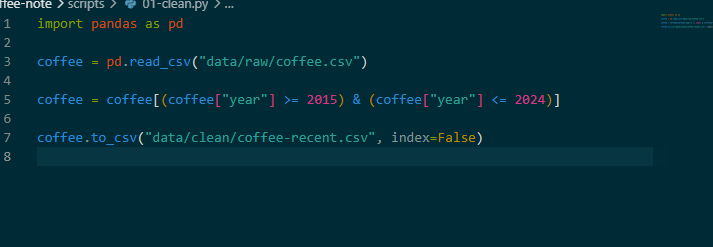


import pandas as pd

coffee = pd.read_csv("data/raw/coffee.csv")

coffee = coffee[(coffee["year"] >= 2015) & (coffee["year"] <= 2024)]

coffee.to_csv("data/clean/coffee-recent.csv", index=False)


### Task 04

Add a chunk to `note.qmd` that loads `data/clean/coffee-recent.csv` with a relative path. The chunk must not show its code or any output in the rendered document. *Hint: one chunk option does both at once; it is in the lecture 10 options table.*


```{python}
#| include: false

import pandas as pd

coffee = pd.read_csv("data/clean/coffee-recent.csv")
```


### Task 05

Add a table of mean coffee consumption and mean happiness by country, sorted by coffee consumption, highest first. Give the chunk a label starting with `tbl-` and a caption, and reference the table in your prose with `@tbl-...` so it renders as a numbered link. *Hint: one mean per country is a group-by job, covered in the [pandas group by guide](https://pandas.pydata.org/docs/user_guide/groupby.html). `sort_values` has an `ascending` parameter. A table caption uses `tbl-cap`, the table version of `fig-cap`.*

## Coffee Consumption and Happiness by Country

Table @tbl-coffee shows the average coffee consumption and happiness by country.

```{python}
#| label: tbl-coffee
#| tbl-cap: "Average Coffee Consumption and Happiness by Country"

coffee_table = coffee.groupby("country")[["coffee_consumption", "happiness"]].mean()

coffee_table = coffee_table.sort_values("coffee_consumption", ascending=False)

coffee_table
```


### Task 06

Add a scatter plot of coffee consumption against happiness score. Give the chunk a `fig-` label and a `fig-cap` caption, and reference it in your prose with `@fig-...`. One sentence of honest commentary is welcome: the note should not claim that coffee causes happiness. *Hint: matplotlib names its scatter plot function after the plot type; the rest follows the lecture 10 plotting chunks.*


## Coffee Consumption and Happiness

Figure @fig-coffee shows the relationship between coffee consumption and happiness, but it does not mean coffee causes happiness.

```{python}
#| label: fig-coffee
#| fig-cap: "Coffee Consumption vs. Happiness Score"

import matplotlib.pyplot as plt

plt.scatter(coffee["coffee_consumption"], coffee["happiness"])
plt.xlabel("Coffee Consumption")
plt.ylabel("Happiness Score")
plt.title("Coffee Consumption vs. Happiness")
plt.show()
```

### Task 07

Somewhere in your prose, report the number of rows in the clean dataset and the overall mean happiness score using inline code, so both numbers change if the data changes. No hard-typed numbers. *Hint: inline code appeared in the lecture 11 slide "A worked example: report.qmd". If a number prints as `np.float64(...)`, wrap it in `float()` before rounding.*


The clean dataset has `{python} len(coffee)` rows, and the mean happiness score is `{python} round(float(coffee["happiness"].mean()), 2)`.


### Task 08

Create `references.bib` in the project root with exactly these three entries:

```bibtex
@article{marlowe2023coffee,
  title={Coffee consumption and subjective wellbeing in high-income countries},
  author={Marlowe, Ada and Chen, Ruth},
  journal={Journal of Beverage Economics},
  volume={18},
  number={2},
  pages={101--119},
  year={2023}
}

@book{okafor2021brew,
  title={The Global Brew: An Economic History of Coffee},
  author={Okafor, Chidi},
  publisher={Meridian Press},
  address={London},
  year={2021}
}

@article{silva2024caffeine,
  title={Caffeine, mood, and productivity: a review},
  author={Silva, Beatriz and Haugen, Lars},
  journal={Review of Behavioural Nutrition},
  volume={9},
  number={1},
  pages={44--61},
  year={2024}
}
```

(The references are invented for this assignment; do not look for the papers.) Point the YAML at the file, then cite Marlowe and Chen in the flow of a sentence, cite Okafor in parentheses with page 12, and cite Silva and Haugen once, in either form. Only cited entries appear in the reference list. The reference list must appear at the end of the rendered note.

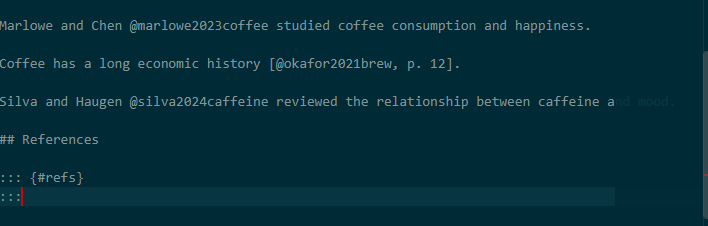
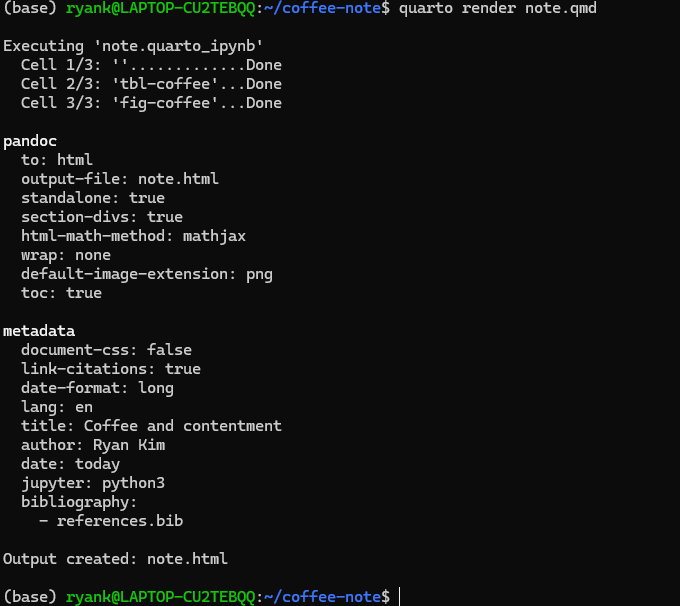

### Task 09

Render `note.qmd` to HTML and to PDF from the command line. Both files stay in the project folder for submission. Paste the two commands into the answer cell. If the PDF render fails, read the error before anything else: the usual cause is a missing TinyTeX.

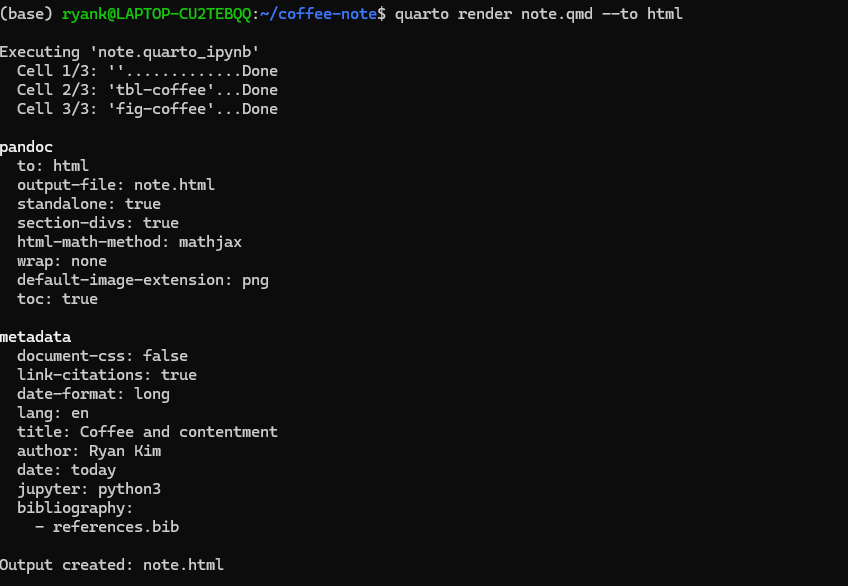

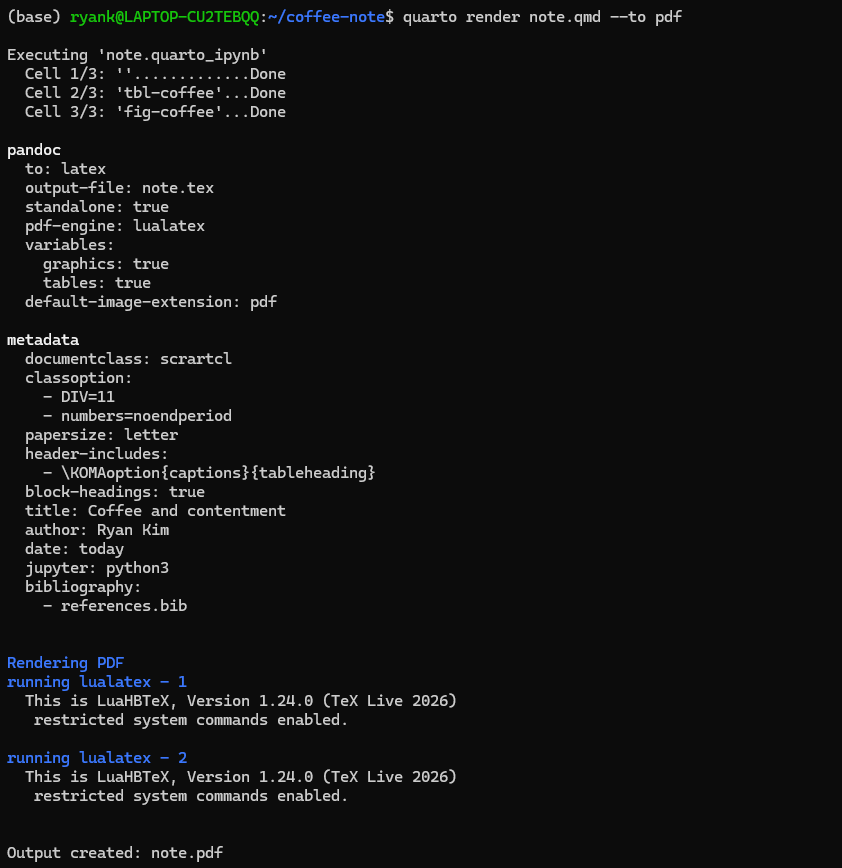

### Task 10

Add a parameter `country` with the default value `"Finland"` in a cell tagged `parameters`, placed at the top of the document, right after the YAML header. Add a short section "Country in focus" that filters the clean data to that country and reports, using inline code, the country's name and its mean happiness score.

Then render two versions from the command line, with output names `note-finland.html` and `note-brazil.html`, passing `Finland` and `Brazil` as the parameter. Paste both commands into the answer cell. Overriding a parameter needs the `papermill` package, so install it first. *Hint: the flag that overrides a parameter is on the lecture 11 slide "Parameterised reports"; the flag that renames the output is on "From one report to a pipeline".*

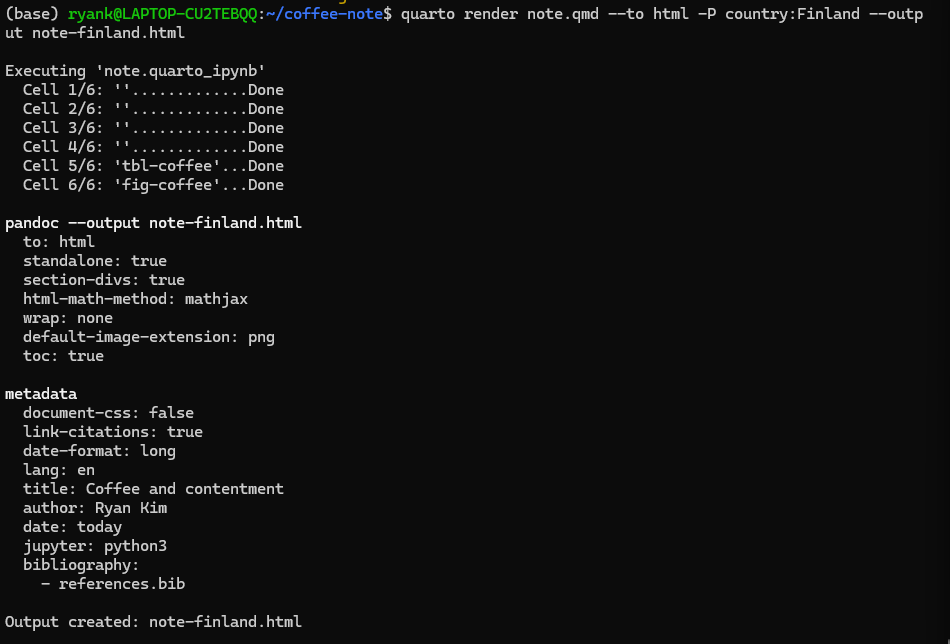

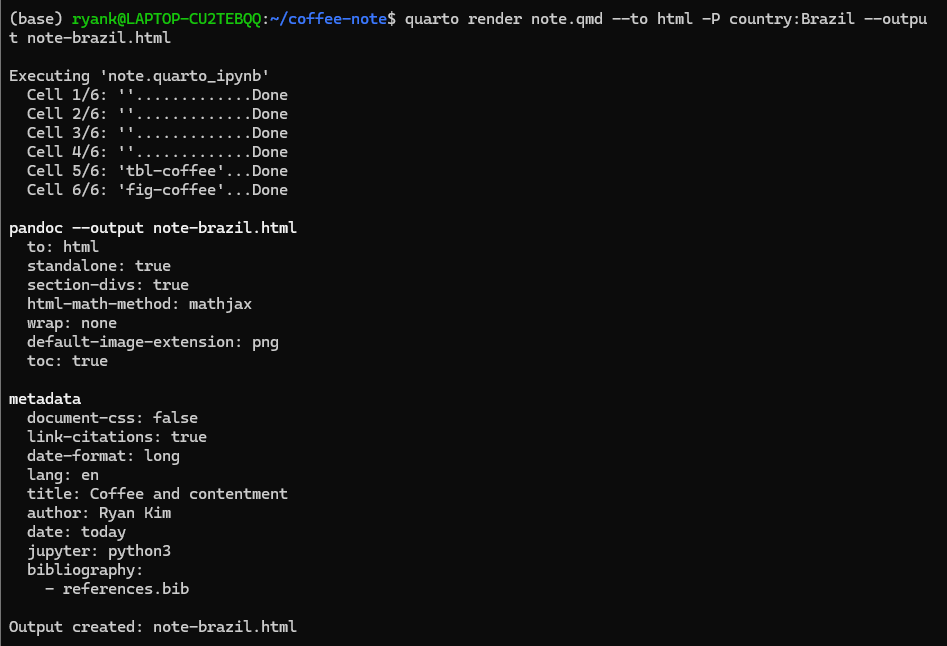

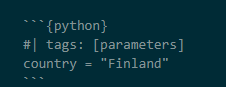

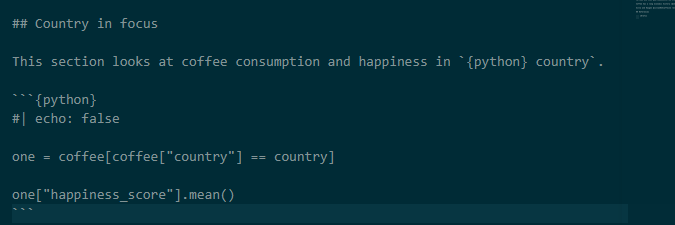

quarto render note.qmd --to html -P country:Finland --output note-finland.html

quarto render note.qmd --to html -P country:Brazil --output note-brazil.html



### Task 11

Complete `README.md` so that a stranger could rebuild your project: one line on what the note is, the data source with the date you downloaded it, the exact commands to rebuild everything in order (including the two parameterised renders), and the Python and package versions you used. Keep the README free of absolute paths too: if you need `QUARTO_PYTHON` on your machine, describe it in words instead of pasting your path.

Then, in the answer cell, in no more than 80 words: which reproducibility habits from lecture 10 does your submission satisfy, and which one is weakest?

My project follows reproducibility practices by including code, data, instructions to rebuild the reports. I kept the raw data unchanged and used relative paths so others can run withhout issues. The weakest part is the environment because I listed the Python and package versions but didn't include a way to automatically install everything.